In [1]:
%load_ext autoreload
%autoreload 2
import xarray as xr
import numpy as np
import xesmf as xe
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from regional_mom6 import regridding as rgd
from regridding_analysis import *

In [2]:
directions = ["north", "south", "east"]
weights = {}
raw_ds = {}
regridded_ds = {}
coords = {}
for direction in directions:
    weights[direction] = xr.open_dataset(f"/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_interpolated_data/{direction}_weights.nc")
    raw_ds[direction] = xr.open_dataset(f"/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/raw_interpolated_data/DIC_{direction}_vfilled.nc")
    regridded_ds[direction] = xr.open_dataset(f"/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/regridded_interpolated_data/DIC_{direction}_regridded.nc")

hgrid = xr.open_dataset("/glade/derecho/scratch/manishrv/croc_input/gustavo-glorys-1/ocnice/ocean_hgrid.nc")

coords["north"] = rgd.coords(hgrid, "north", "segment_002")
coords["south"] = rgd.coords(hgrid, "south", "segment_001")
coords["east"] = rgd.coords(hgrid, "east", "segment_003")
# Access variables
cols = {}
rows = {}
weights_vals = {}
flat_tlon = {}
flat_tlat = {}
for direction in directions:
    cols[direction] = weights[direction].col.values
    rows[direction] = weights[direction].row.values
    weights_vals[direction] = weights[direction].S.values
    flat_tlon[direction] = raw_ds[direction]['TLONG'].values.flatten()
    flat_tlat[direction] = raw_ds[direction]['TLAT'].values.flatten()


In [78]:
from CrocoDash.grid import Grid
from CrocoDash.topo import Topo


grid = Grid.from_supergrid("//glade/work/manishrv/rm6_work/mom_input/angle_calc.3.2n3b/hgrid.nc")

bathymetry_path="/glade/work/manishrv/rm6_work/mom_input/angle_calc.3.2n3b/bathymetry.nc"

topo = Topo.from_topo_file(
    grid = grid,
    topo_file_path=bathymetry_path,
    min_depth = 9.95,
)


In [56]:
ocean_static = xr.open_dataset("/glade/derecho/scratch/manishrv/angle_calc.2.2n3b/run/run_200/ocean_static.nc")

t_points = rgd.get_hgrid_arakawa_c_points(hgrid, "t")
v_points = rgd.get_hgrid_arakawa_c_points(hgrid, "v")
u_points = rgd.get_hgrid_arakawa_c_points(hgrid, "u")
q_points = rgd.get_hgrid_arakawa_c_points(hgrid, "q")

# Put in Ocean Static
ocean_static["tlon"] = (("yh","xh"),(t_points.tlon.values))
ocean_static["tlat"] = (("yh","xh"),(t_points.tlat.values))
ocean_static["ulon"] = (("yh","xq"),(u_points.ulon.values))
ocean_static["ulat"] = (("yh","xq"),(u_points.ulat.values))
ocean_static["qlon"] = (("yq","xq"),(q_points.qlon.values))
ocean_static["qlat"] = (("yq","xq"),(q_points.qlat.values))
ocean_static["vlon"] = (("yq","xh"),(v_points.vlon.values))
ocean_static["vlat"] = (("yq","xh"),(v_points.vlat.values))
# Create filter masks
filter_mask_t = ocean_static["wet"] == 0
filter_mask_c = ocean_static["wet_c"] == 0
filter_mask_v = ocean_static["wet_v"] == 0
filter_mask_u = ocean_static["wet_u"] == 0


In [60]:
ocean_static["wet_u"]

<xarray.DataArray 'wet_u' (yh: 780, xq: 741)>
array([[0., 0., 0., ..., 1., 1., 1.],
       [0., 0., 0., ..., 1., 1., 1.],
       [0., 0., 0., ..., 1., 1., 1.],
       ...,
       [0., 0., 0., ..., 1., 1., 1.],
       [0., 0., 0., ..., 1., 1., 1.],
       [0., 0., 0., ..., 1., 1., 1.]], dtype=float32)
Coordinates:
  * yh       (yh) float64 5.243 5.326 5.409 5.492 ... 53.78 53.82 53.86 53.89
  * xq       (xq) float64 -98.0 -97.92 -97.83 -97.75 ... -36.5 -36.42 -36.33
Attributes:
    long_name:      0 if land, 1 if ocean at zonal velocity (Cu) points
    cell_methods:   time: point
    interp_method:  none

In [85]:
topo.min_depth  = 46
np.where(topo.umask != ocean_static["wet_u"])

(array([  0,   0,   0, ..., 779, 779, 779]),
 array([544, 545, 546, ..., 472, 473, 474]))

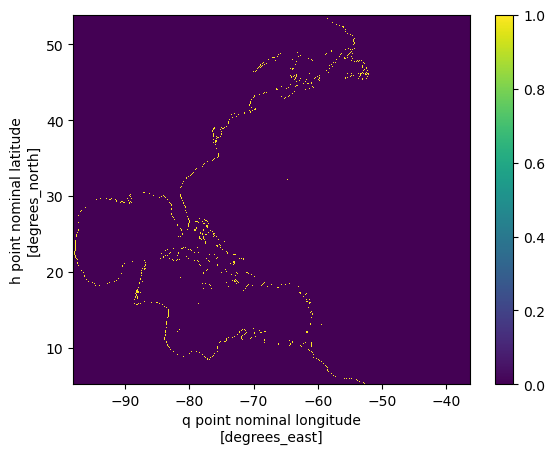

In [65]:
(topo.umask - ocean_static["wet_u"]).plot()

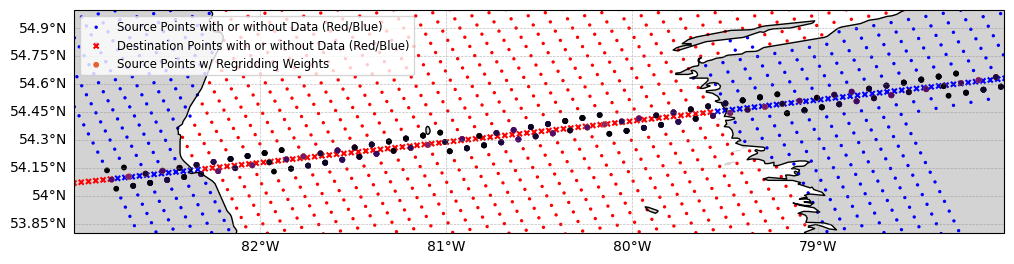

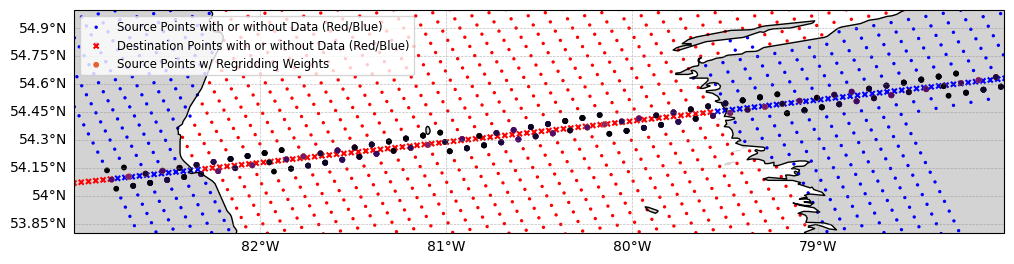

In [3]:

plot_regridding_snapshot(raw_ds["north"], regridded_ds["north"], weights["north"], raw_var_name = "DIC", regrid_var_name="__xarray_dataarray_variable__")

Point Index: 430 Latitude: 54.16295861091795 Longitude: -82.13910920260378 is:  1976.1132 from #Nans in Source Point Values: 0


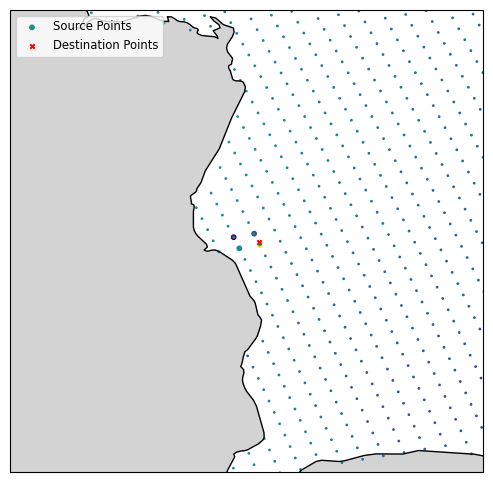

In [4]:

regridding_point_analysis(raw_ds["north"], regridded_ds["north"], weights["north"],[430], raw_var_name = "DIC", regrid_var_name="__xarray_dataarray_variable__")

In [ ]:
ocean_static = xr.open_dataset("/glade/derecho/scratch/manishrv/angle_calc.2.2n3b/run/run_200/ocean_static.nc")


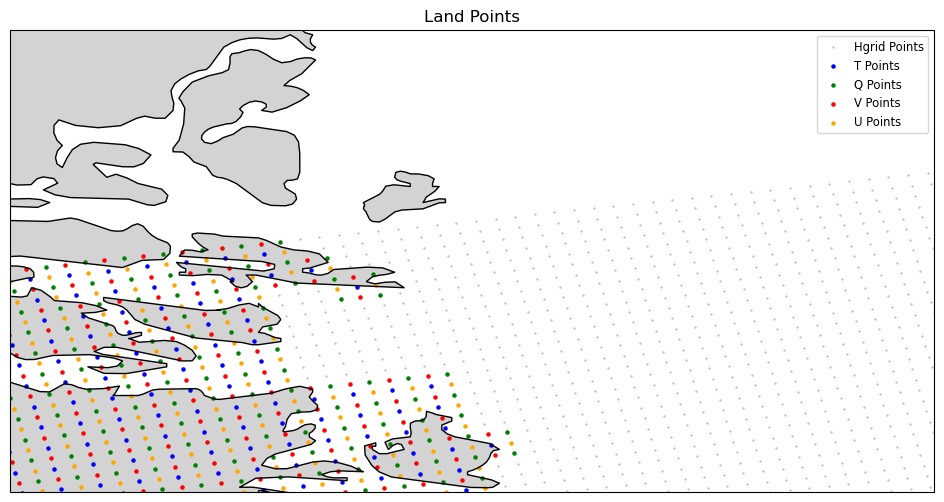

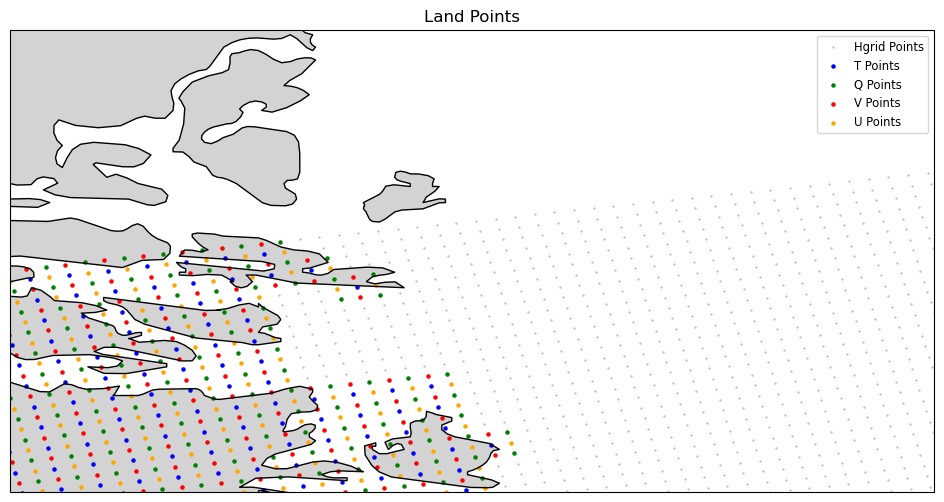

In [6]:

plot_region_mask(ocean_static, hgrid)

    

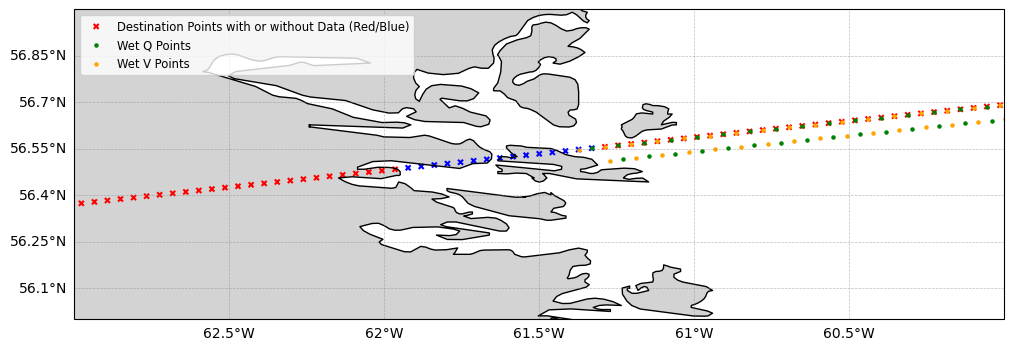

In [ ]:
plot_boundary_mask(ocean_static, hgrid, regridded_ds["north"],regrid_var_name="__xarray_dataarray_variable__")

# Summary
if the source points have any nans, anywhere in the bilinear interpolation (on the surface) the destination point is Nan
How does this change with depth? And why is it that the regridding returns zero, where there is no weight? How does that work?
Depth levels are not regridded independently, and it seems like regridding returns zeros wherever there isn't weight.

# next work
figure out the horizontal masks (land mask) between the two and figure out the vertical mask (bathymetry) between the two